# Artificial Scattering for Ray Effect Mitigation

Discrete ordinates (S$_N$) only transports particles along a finite set of
directions. Around a localized source in a weakly scattering medium, the flux
streams out along those directions and leaves unphysical streaks between them.
These are called *ray effects*.

ANTS can reduce ray effects with artificial scattering (as-S$_N$), following
Frank, Kusch, Camminady & Hauck (2020), "Ray Effect Mitigation for the Discrete
Ordinates Method Using Artificial Scattering", *Nuclear Science and
Engineering*. A forward-peaked scattering term is added to the transport
equation:

$$
\Omega_q \cdot \nabla \psi_q + (\sigma_t + \sigma_{as})\, \psi_q
    = \sigma_s \phi + \sum_p M_{as}[q, p]\, \psi_p + q_\text{ext}
$$

Each row of $M_{as}$ sums to $\sigma_{as}$, so the added out-scattering and
in-scattering balance and particles are conserved. The kernel only couples
nearby ordinates, which smears flux into the gaps between directions.

Artificial scattering is enabled through two `SolverData` fields:

* `sigma_as`: the artificial scattering strength (default `0.0`, disabled)
* `beta_as`: the kernel width (default `4.5`; larger is wider)

This example solves the same problem three ways:

1. standard S$_N$ with a coarse quadrature,
2. as-S$_N$ with the same coarse quadrature, and
3. a fine quadrature as the reference.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm
from scipy.interpolate import RegularGridInterpolator

import ants
from ants.datatypes import (
    GeometryData,
    MaterialData,
    SolverData,
    SourceData,
    SpatialDiscretization,
)
from ants.fixed2d import fixed_source

## Problem setup

A 6 cm x 6 cm pure absorber ($\sigma_t = 1$ cm$^{-1}$, no scattering) with a
small isotropic source at the center and vacuum boundaries. With no physical
scattering to redistribute particles, this is a worst case for ray effects.

Step differencing is used because it keeps the flux positive near the
localized source, which is needed for the log-scale plots below.

In [2]:
cells = 100
length = 6.0
delta = np.repeat(length / cells, cells)
centers = (np.arange(cells) + 0.5) * delta[0]

mat_data = MaterialData(
    total=np.array([[1.0]]),
    scatter=np.array([[[0.0]]]),
    fission=np.array([[[0.0]]]),
)

# Isotropic source in the central 4 x 4 cells (0.24 cm x 0.24 cm)
external = np.zeros((cells, cells, 1, 1))
middle = slice(cells // 2 - 2, cells // 2 + 2)
external[middle, middle] = 1.0

sources = SourceData(
    external=external,
    boundary_x=np.zeros((2, 1, 1, 1)),
    boundary_y=np.zeros((2, 1, 1, 1)),
)

geometry = GeometryData(
    medium_map=np.zeros((cells, cells), dtype=np.int32),
    delta_x=delta,
    delta_y=delta,
    bc_x=[0, 0],
    bc_y=[0, 0],
    geometry=3,  # 2D slab
    space_disc=SpatialDiscretization.STEP,
)


def solve(angles, sigma_as=0.0, beta_as=4.5):
    """Return the scalar flux for a quadrature with angles per dimension."""
    quadrature = ants.angular_xy(angles)
    solver = SolverData(sigma_as=sigma_as, beta_as=beta_as)
    flux = fixed_source(mat_data, sources, geometry, quadrature, solver)
    return flux[..., 0]

## Solving with and without artificial scattering

`angular_xy(4)` gives 16 directions, which is coarse enough to show strong ray
effects. The reference uses `angular_xy(32)` (1024 directions). At that
resolution the flux changes by less than 0.2% from `angular_xy(24)`.

In [3]:
coarse = 4
sigma_as = 3.0

flux_ref = solve(32)
flux_sn = solve(coarse)
flux_as = solve(coarse, sigma_as=sigma_as)


def rel_error(flux):
    return np.linalg.norm(flux - flux_ref) / np.linalg.norm(flux_ref)


print(f"Standard SN relative L2 error: {rel_error(flux_sn):.3f}")
print(f"as-SN       relative L2 error: {rel_error(flux_as):.3f}")

Standard SN relative L2 error: 0.117
as-SN       relative L2 error: 0.076


The flux falls off by several orders of magnitude from the source, so it
is plotted on a log scale. All three panels share one color scale.

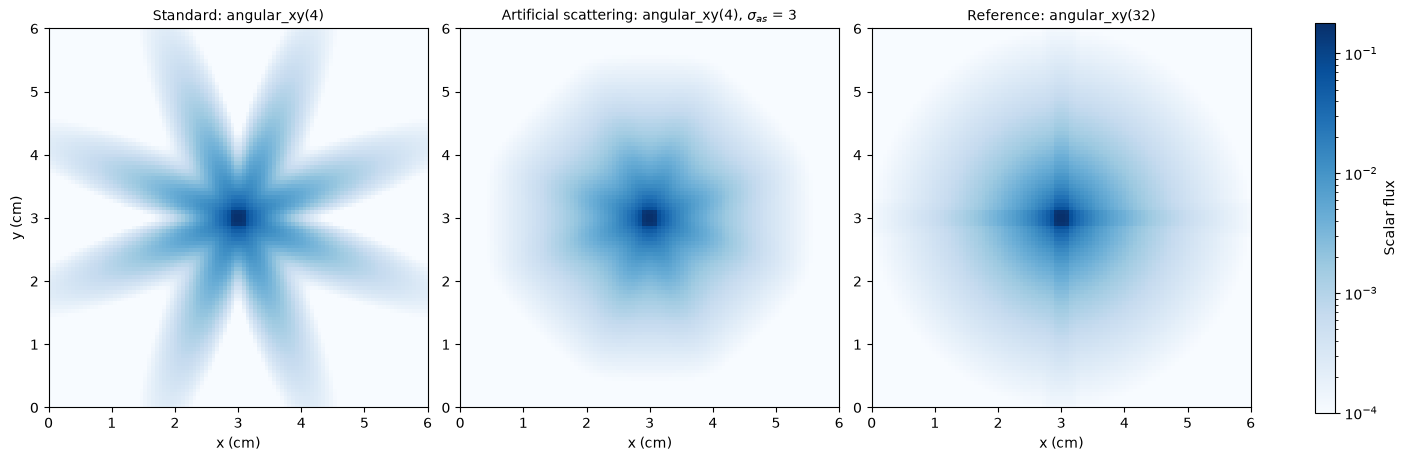

In [4]:
panels = [
    (flux_sn, f"Standard: angular_xy({coarse})"),
    (flux_as, f"Artificial scattering: angular_xy({coarse}), $\\sigma_{{as}}$ = {sigma_as:g}"),
    (flux_ref, "Reference: angular_xy(32)"),
]
norm = LogNorm(vmin=1e-4, vmax=flux_ref.max())

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), constrained_layout=True)
for ax, (flux, title) in zip(axes, panels):
    mesh = ax.pcolormesh(
        centers, centers, flux.T, norm=norm, cmap="Blues", shading="auto"
    )
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("x (cm)")
    ax.set_aspect("equal")
axes[0].set_ylabel("y (cm)")
fig.colorbar(mesh, ax=axes, label="Scalar flux", shrink=0.9)
plt.show()

With 16 directions the standard solution is a set of distinct beams with
almost no flux between them. Artificial scattering spreads flux into those
gaps, and the result looks much closer to the reference.

A sharper test is the flux around a circle centered on the source. Without ray
effects it should be close to the reference profile at every angle. The
reference profile is not perfectly flat because the source is a square on a
Cartesian grid.

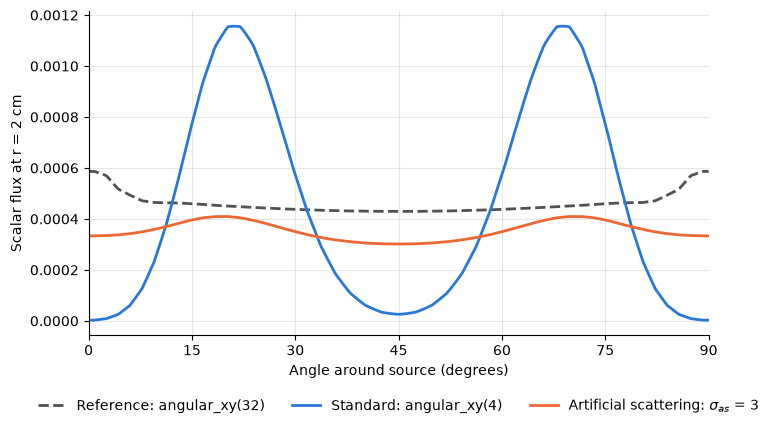

Mean flux on the circle / reference: standard 0.99, as-SN 0.77
Total flux / reference:              as-SN 1.016


In [5]:
radius = 2.0
theta = np.linspace(0.0, 0.5 * np.pi, 361)  # one quadrant, by symmetry


def on_circle(flux):
    points = np.column_stack(
        [0.5 * length + radius * np.cos(theta), 0.5 * length + radius * np.sin(theta)]
    )
    return RegularGridInterpolator((centers, centers), flux)(points)


fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(np.degrees(theta), on_circle(flux_ref), color="#52514e", lw=2,
        ls="--", label="Reference: angular_xy(32)")
ax.plot(np.degrees(theta), on_circle(flux_sn), color="#2a78d6", lw=2,
        label=f"Standard: angular_xy({coarse})")
ax.plot(np.degrees(theta), on_circle(flux_as), color="#eb6834", lw=2,
        label=f"Artificial scattering: $\\sigma_{{as}}$ = {sigma_as:g}")
ax.set_xlabel("Angle around source (degrees)")
ax.set_ylabel(f"Scalar flux at r = {radius:g} cm")
ax.set_xlim(0, 90)
ax.set_xticks(np.arange(0, 91, 15))
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3)
plt.show()

ratio_sn = on_circle(flux_sn).mean() / on_circle(flux_ref).mean()
ratio_as = on_circle(flux_as).mean() / on_circle(flux_ref).mean()
total_as = flux_as.sum() / flux_ref.sum()
print(f"Mean flux on the circle / reference: standard {ratio_sn:.2f}, as-SN {ratio_as:.2f}")
print(f"Total flux / reference:              as-SN {total_as:.3f}")

Artificial scattering removes the oscillation, but it also lowers the flux
on the circle relative to the reference. This is a bias of the method in an
absorber. Each artificial scattering event redirects a particle slightly, so
the particle travels a longer path to reach the circle, and more particles
are absorbed on the way. The total flux, which is proportional to total track
length, is slightly higher than the reference for the same reason.

## Choosing $\sigma_{as}$

Artificial scattering trades ray effects for added smoothing. Too little
leaves the beams in place. Too much over-smooths the solution and acts like
a real scattering medium. The sweep below tracks two measures:

* the coefficient of variation (CoV) of the flux on the circle above, which
  measures how strong the ray effects are, and
* the relative L2 error against the reference over the whole domain.

Larger `sigma_as` also needs more source iterations, because the artificial
in-scattering term is lagged between iterations.

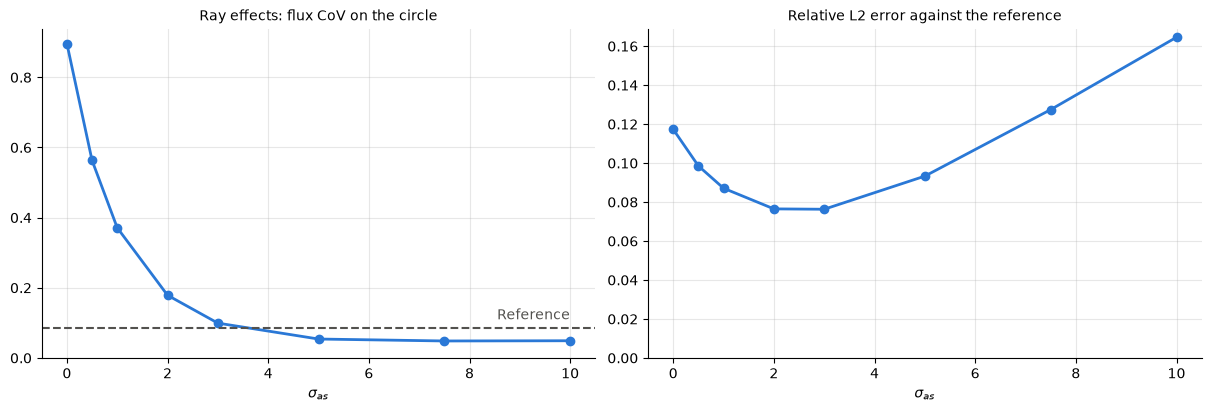

sigma_as =   0.0   CoV = 0.896   L2 error = 0.117
sigma_as =   0.5   CoV = 0.563   L2 error = 0.099
sigma_as =   1.0   CoV = 0.371   L2 error = 0.087
sigma_as =   2.0   CoV = 0.179   L2 error = 0.076
sigma_as =   3.0   CoV = 0.099   L2 error = 0.076
sigma_as =   5.0   CoV = 0.054   L2 error = 0.093
sigma_as =   7.5   CoV = 0.048   L2 error = 0.127
sigma_as =  10.0   CoV = 0.049   L2 error = 0.165


In [6]:
sweep = np.array([0.0, 0.5, 1.0, 2.0, 3.0, 5.0, 7.5, 10.0])
cov, error = [], []
for value in sweep:
    flux = solve(coarse, sigma_as=value)
    ring = on_circle(flux)
    cov.append(ring.std() / ring.mean())
    error.append(rel_error(flux))

ring_ref = on_circle(flux_ref)
cov_ref = ring_ref.std() / ring_ref.mean()

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
ax0.plot(sweep, cov, color="#2a78d6", lw=2, marker="o", ms=6)
ax0.axhline(cov_ref, color="#52514e", lw=1.5, ls="--")
ax0.annotate("Reference", (sweep[-1], cov_ref), xytext=(0, 6),
             textcoords="offset points", ha="right", color="#52514e")
ax0.set_title("Ray effects: flux CoV on the circle", fontsize=10)
ax0.set_ylim(bottom=0)

ax1.plot(sweep, error, color="#2a78d6", lw=2, marker="o", ms=6)
ax1.set_title("Relative L2 error against the reference", fontsize=10)
ax1.set_ylim(bottom=0)

for ax in (ax0, ax1):
    ax.set_xlabel("$\\sigma_{as}$")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

for value, c, e in zip(sweep, cov, error):
    print(f"sigma_as = {value:5.1f}   CoV = {c:.3f}   L2 error = {e:.3f}")

The ray effects fall quickly as $\sigma_{as}$ increases, but the overall
error is lowest around $\sigma_{as} \approx 2$-$3$ for this problem. Past that
point the extra smoothing costs more accuracy than it recovers. Once the CoV
drops below the reference value, the solution is smoother than the true flux,
which is a clear sign of too much artificial scattering. The best value
depends on the problem, the quadrature and the mesh, so it is worth running a
short sweep like this one for new problems.

## Notes

* Artificial scattering is available in the 2D solvers: `fixed2d`, `timed2d`
  (all time discretizations) and `hybrid2d`. It has no effect when
  `sigma_as = 0`. It is not used by `critical2d` or `vhybrid2d`.
* `beta_as` sets the kernel width $\epsilon = \beta / N$, where $N$ is the
  number of directions. Typical values are about 4.5 for explicit and 4.0
  for implicit schemes.
* Artificial scattering does not replace angular refinement. It makes a
  coarse quadrature more usable, but the converged answer still comes from a
  finer quadrature.